# 04 Modeling
Reads data_stats.csv. Baseline, CV, feature selection, tuning, final test, saves the model.
CV validation years: 2022-23, 2023-24, 2024-25. Test: Oct 2025 - Sep 2026, used once at the end.

In [377]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

In [378]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [379]:
BASE = '/content/drive/MyDrive/ml/weather'

In [380]:
data = pd.read_csv(
    f'{BASE}/data_stats.csv',
    index_col=0,
    parse_dates=True
    )
data = data.dropna(subset=['pm10_mean'])

## 1. CV setup
3 folds, each one validates on one year. A change is kept only if all 3 folds get better.
Baseline = yesterday's PM10 (pm10_lag1).

In [381]:
def cv_mae(df, features, target='pm10_mean', params=None):
  fold_ends = ["2022-09-30", "2023-09-30", "2024-09-30"]
  maes = []
  X = df[features]
  y = df[target]
  for end in fold_ends:
    if params is None:
      params = {}
    lgbm = LGBMRegressor(verbose=-1, **params)
    val_start = pd.to_datetime(end) + pd.Timedelta(days=1)
    val_end = pd.to_datetime(end) + pd.DateOffset(years=1)

    x_train = X.loc[:end]
    x_val = X.loc[val_start:val_end]
    y_train = y.loc[:end]
    y_val = y.loc[val_start:val_end]

    lgbm.fit(x_train, np.log1p(y_train))
    pred = lgbm.predict(x_val)
    pred = np.expm1(pred)
    mae = (y_val - pred).abs().mean()
    maes.append(mae)
  return maes

In [382]:
def baseline_cv(df, target='pm10_mean'):
  fold_ends = ["2022-09-30", "2023-09-30", "2024-09-30"]
  maes = []
  for end in fold_ends:
    val_start = pd.to_datetime(end) + pd.Timedelta(days=1)
    val_end = pd.to_datetime(end) + pd.DateOffset(years=1)
    val = df.loc[val_start:val_end]
    maes.append((val[target] - val['pm10_lag1']).abs().mean())
  return maes

baseline_cv(data)

[np.float64(9.662923775051361),
 np.float64(9.624763446586643),
 np.float64(9.375071801908962)]

## 2. Base features and params
p22 = Optuna trial 22 on the v1 features. Kept fixed during feature selection.

In [383]:
base_features = ['temp_mean', 'temp_min', 'temp_max', 'humidity_mean', 'precipitation_sum',
                'wind_speed_mean', 'wind_speed_max', 'wind_gusts_max',
                 'cloud_cover_mean', 'wind_sin', 'wind_cos',
                 'pm10_lag1', 'pm10_lag7', 'pm10_roll7',
                 'dayofyear', 'pressure_mean']

In [384]:
p22 = {'learning_rate' : 0.0118, 'n_estimators' : 456, 'num_leaves' : 21, 'min_child_samples' : 108}
print(cv_mae(data, base_features, params=p22))

[np.float64(7.959352150115177), np.float64(8.976266849918874), np.float64(7.707279590274317)]


## 3. Feature selection

In [385]:
def backward_test(data, base_features, params):
  results = {}
  results['base'] = cv_mae(data, base_features, params=params)

  for c in base_features:
    features = [a for a in base_features if a!=c]
    results['-' + c] = cv_mae(data, features, params=params)
  backward_table = pd.DataFrame(results, index=['2022-2023', '2023-2024', '2024-2025']).T
  backward_table['mean'] = backward_table.mean(axis=1)
  return backward_table

In [386]:
def forward_test(data, base_features, candidates, params):
  results = {}
  results['base'] = cv_mae(data, base_features, params=params)

  for c in candidates:
    results['+' + c] = cv_mae(data, base_features + [c], params=params)
  forward_table = pd.DataFrame(results, index=['2022-2023', '2023-2024', '2024-2025']).T
  forward_table['mean'] = forward_table.mean(axis=1)
  return forward_table


### Backward check
Remove each base feature one at a time.

In [387]:
backward_table = backward_test(data, base_features, params=p22)
backward_table

,2022-2023,2023-2024,2024-2025,mean
base,7.959352,8.976267,7.707280,8.214300
-temp_mean,7.952865,8.973936,7.731885,8.219562
-temp_min,8.003116,9.023678,7.727578,8.251458
-temp_max,8.082629,9.168808,7.684752,8.312063
-humidity_mean,7.908118,9.154178,7.862724,8.308340
-precipitation_sum,7.989887,9.023727,7.685772,8.233129
-wind_speed_mean,8.143381,8.922419,7.669281,8.245027
-wind_speed_max,7.961868,8.986270,7.662642,8.203594
-wind_gusts_max,7.991694,9.022816,7.714590,8.243034
-cloud_cover_mean,7.912006,8.982703,7.740862,8.211857


Nothing removed, every removal makes at least one fold worse.

### Forward selection
Each round tries all remaining candidates and adds the best one that improves all 3 folds.

In [388]:
all_candidates = ['pm10_lag2', 'pm10_diff', '3days_max', '3days_std', 'dayofweek',
                  'no2_lag1', 'so2_lag1', 'low_wind_speed', 'night_wind_speed',
                  'temp_dif', 'pressure_dif', 'heating_season', 'pollution',
                  'U_wind', 'V_wind']

In [389]:
selected = []
remaining = [x for x in all_candidates if x not in selected]
forward_test(data, base_features + selected, remaining, params=p22)

,2022-2023,2023-2024,2024-2025,mean
base,7.959352,8.976267,7.707280,8.214300
+pm10_lag2,7.926730,9.000641,7.667098,8.198156
+pm10_diff,7.996585,9.046152,7.669420,8.237386
+3days_max,7.961476,8.974081,7.680614,8.205391
+3days_std,7.951061,8.923881,7.704883,8.193275
+dayofweek,7.959352,8.972310,7.674813,8.202158
+no2_lag1,7.990951,9.012652,7.631309,8.211637
+so2_lag1,8.002350,8.982082,7.672180,8.218870
+low_wind_speed,7.914784,8.983204,7.686777,8.194922
+night_wind_speed,7.981373,8.963332,7.716282,8.220329


Round 1: added temp_dif

In [390]:
selected = ['temp_dif']
remaining = [x for x in all_candidates if x not in selected]
forward_test(data, base_features + selected, remaining, params=p22)

,2022-2023,2023-2024,2024-2025,mean
base,7.941466,8.959536,7.451819,8.117607
+pm10_lag2,7.966354,9.044404,7.361773,8.124177
+pm10_diff,7.999684,9.006926,7.468664,8.158425
+3days_max,7.937330,8.937114,7.427971,8.100805
+3days_std,7.976870,8.876913,7.434069,8.095951
+dayofweek,7.941466,8.961922,7.433775,8.112388
+no2_lag1,7.941158,9.083533,7.415858,8.146850
+so2_lag1,8.010535,8.890115,7.445071,8.115240
+low_wind_speed,7.866650,8.987392,7.416369,8.090137
+night_wind_speed,7.948977,9.033064,7.451302,8.144448


Round 2: added 3days_max

In [391]:
selected = ['temp_dif', '3days_max']
remaining = [x for x in all_candidates if x not in selected]
forward_test(data, base_features + selected, remaining, params=p22)

,2022-2023,2023-2024,2024-2025,mean
base,7.937330,8.937114,7.427971,8.100805
+pm10_lag2,7.928464,8.944500,7.323692,8.065552
+pm10_diff,7.984127,8.994255,7.424140,8.134174
+3days_std,7.977761,8.818591,7.417498,8.071283
+dayofweek,7.937330,8.944711,7.429447,8.103829
+no2_lag1,7.905609,9.038490,7.418257,8.120785
+so2_lag1,8.001338,8.881464,7.448687,8.110496
+low_wind_speed,7.842941,8.964296,7.383452,8.063563
+night_wind_speed,7.903896,8.961996,7.423856,8.096583
+pressure_dif,7.889845,8.869095,7.452939,8.070626


Round 3: added U_wind

In [392]:
selected = ['temp_dif', '3days_max', 'U_wind']
remaining = [x for x in all_candidates if x not in selected]
forward_test(data, base_features + selected, remaining, params=p22)

,2022-2023,2023-2024,2024-2025,mean
base,7.931695,8.921556,7.414125,8.089126
+pm10_lag2,7.898833,8.954792,7.324759,8.059461
+pm10_diff,7.936931,9.010526,7.418982,8.122146
+3days_std,7.954429,8.838068,7.435096,8.075864
+dayofweek,7.931695,8.924552,7.410382,8.088876
+no2_lag1,7.889222,9.024204,7.398299,8.103908
+so2_lag1,8.016598,8.902354,7.423632,8.114195
+low_wind_speed,7.836971,8.926360,7.352778,8.038703
+night_wind_speed,7.891563,8.978835,7.396583,8.088994
+pressure_dif,7.909705,8.940178,7.448422,8.099435


Round 4: nothing passes, stop.

In [393]:
final_features = base_features + ['temp_dif', '3days_max', 'U_wind']
len(final_features)

19

## 4. Tuning
Optuna again on the final features, starting from p22.

In [394]:
%pip install optuna
import optuna

def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.003, 0.1, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "num_leaves": trial.suggest_int("num_leaves", 8, 64),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 150),
    }
    return np.mean(cv_mae(data, final_features, params=params))

study = optuna.create_study(direction="minimize",
                            sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial(p22)
study.optimize(objective, n_trials=50)

[I 2026-10-28 21:57:04,705] A new study created in memory with name: no-name-999641e3-52b4-4506-954f-e6aa8c9cc19f
[I 2026-10-28 21:57:05,477] Trial 0 finished with value: 8.08912551471335 and parameters: {'learning_rate': 0.0118, 'n_estimators': 456, 'num_leaves': 21, 'min_child_samples': 108}. Best is trial 0 with value: 8.08912551471335.
[I 2026-10-28 21:57:07,262] Trial 1 finished with value: 8.423419008334685 and parameters: {'learning_rate': 0.01115579284069578, 'n_estimators': 956, 'num_leaves': 49, 'min_child_samples': 94}. Best is trial 0 with value: 8.08912551471335.
[I 2026-10-28 21:57:07,596] Trial 2 finished with value: 9.574013845703167 and parameters: {'learning_rate': 0.005184641432105231, 'n_estimators': 240, 'num_leaves': 11, 'min_child_samples': 132}. Best is trial 0 with value: 8.08912551471335.
[I 2026-10-28 21:57:08,500] Trial 3 finished with value: 8.521553341933659 and parameters: {'learning_rate': 0.0246914463069284, 'n_estimators': 737, 'num_leaves': 9, 'min_ch

In [395]:
cv_mae(data, final_features, params=p22)

[np.float64(7.931694983672157),
 np.float64(8.921556094823224),
 np.float64(7.414125465644671)]

In [396]:
p27 = {'learning_rate': 0.006533139748319403, 'n_estimators': 515, 'num_leaves': 20, 'min_child_samples': 58}
cv_mae(data, final_features, params=p27)

[np.float64(7.646940752524884),
 np.float64(8.810706721331572),
 np.float64(7.4478798785266305)]

p27 is better on average but worse on 2024-25, so p22 stays.

## 5. Final test

In [397]:
train = data.loc[:"2025-09-30", final_features + ['pm10_mean']]
test = data.loc["2025-10-01":, final_features + ['pm10_mean']]

x_train = train.drop('pm10_mean', axis=1)
y_train = train['pm10_mean']
x_test = test.drop('pm10_mean', axis=1)
y_test = test['pm10_mean']

In [398]:
lgbm = LGBMRegressor(verbose=-1, **p22)
lgbm.fit(x_train, np.log1p(y_train))
pred = pd.Series(np.expm1(lgbm.predict(x_test)), index=y_test.index)

In [399]:
results = pd.DataFrame({
    'MAE':  [(y_test - x_test['pm10_lag1']).abs().mean(), (y_test - pred).abs().mean()],
    'RMSE': [np.sqrt(((y_test - x_test['pm10_lag1']) ** 2).mean()), np.sqrt(((y_test - pred) ** 2).mean())],
}, index=['Baseline (pm10_lag1)', 'Final model'])
results.round(2)

,MAE,RMSE
Baseline (pm10_lag1),10.12,14.03
Final model,7.31,10.10


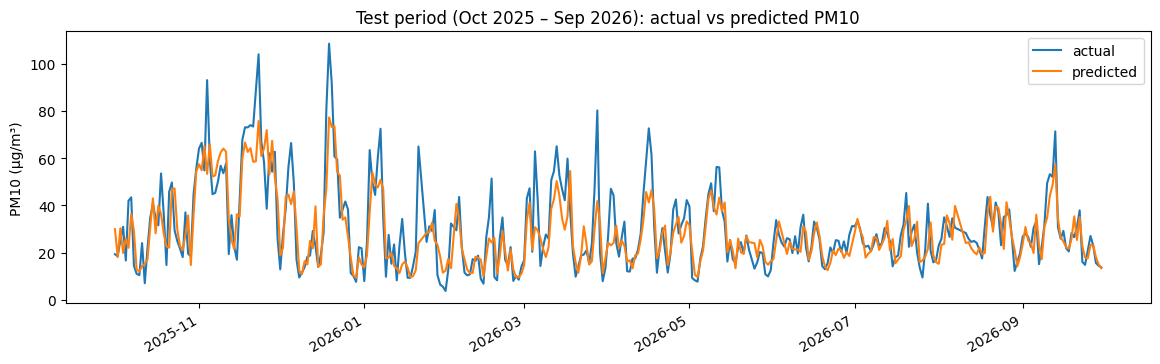

In [400]:
y_test.plot(figsize=(14, 4), label='actual')
pred.plot(label='predicted')
plt.legend()
plt.title('Test period (Oct 2025 – Sep 2026): actual vs predicted PM10')
plt.ylabel('PM10 (µg/m³)')
plt.savefig(f'{BASE}/figures/test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Error analysis

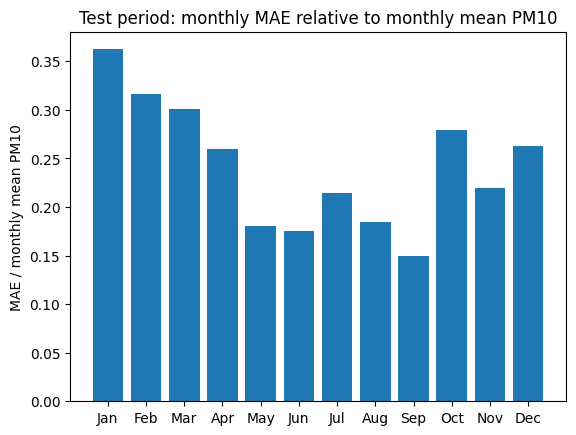

In [401]:
monthly_mae = (y_test - pred).abs().groupby(y_test.index.month).mean()
monthly_mean = y_test.groupby(y_test.index.month).mean()
nmae = (monthly_mae / monthly_mean).rename('nmae')

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.bar(x=[month_names[m - 1] for m in nmae.index], height=nmae.values)
plt.title('Test period: monthly MAE relative to monthly mean PM10')
plt.ylabel('MAE / monthly mean PM10')
plt.savefig(f'{BASE}/figures/monthly_nmae.png', dpi=150, bbox_inches='tight')
plt.show()

In [402]:
worst = (y_test - pred).abs().sort_values(ascending=False).index[:15]
pd.DataFrame({'actual': y_test[worst], 'pred': pred[worst], 'pm10_lag1': x_test.loc[worst, 'pm10_lag1']}).round(1)

,actual,pred,pm10_lag1
2026-01-21,64.9,24.0,20.4
2025-11-04,93.1,53.3,54.8
2026-03-28,80.2,41.8,47.6
2025-12-18,80.6,47.0,28.5
2025-11-26,38.6,71.9,58.4
2026-03-05,62.9,30.8,20.3
2026-04-16,72.6,41.2,58.5
2025-12-19,108.5,77.2,80.6
2025-11-22,88.7,58.6,73.4
2025-11-23,104.0,75.8,88.7


## 7. Feature ablation
Remove each final feature and check the CV MAE.

In [403]:
ablation_table = backward_test(data, final_features, params=p22)
ablation_table

,2022-2023,2023-2024,2024-2025,mean
base,7.931695,8.921556,7.414125,8.089126
-temp_mean,7.927090,8.897062,7.439426,8.087859
-temp_min,7.903062,8.886527,7.438165,8.075918
-temp_max,7.830540,9.000776,7.436433,8.089250
-humidity_mean,7.881134,9.085026,7.509062,8.158407
-precipitation_sum,7.905625,8.910369,7.443908,8.086634
-wind_speed_mean,8.052258,8.976615,7.480213,8.169695
-wind_speed_max,7.931226,8.920559,7.436202,8.095996
-wind_gusts_max,7.943898,8.932622,7.486168,8.120896
-cloud_cover_mean,7.943879,8.897420,7.449480,8.096926


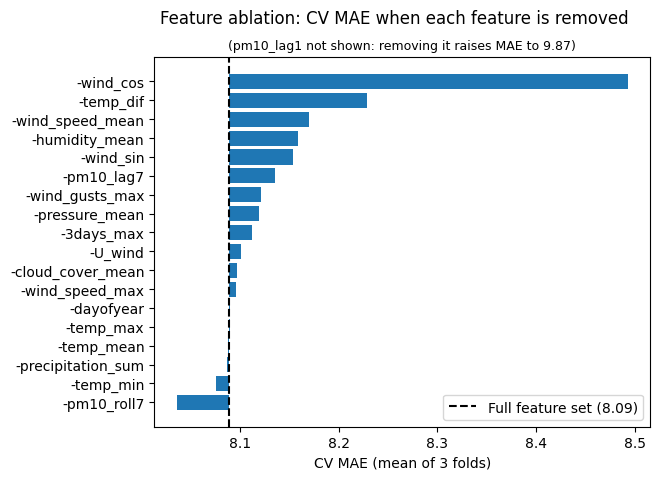

In [404]:
base_mae = ablation_table.loc['base', 'mean']
abl = (ablation_table['mean'].drop(['base', '-pm10_lag1']) - base_mae).sort_values()

plt.barh(y=abl.index, width=abl, left=base_mae)
plt.axvline(base_mae, color='black', linestyle='--', label=f"Full feature set ({base_mae:.2f})")
plt.suptitle('Feature ablation: CV MAE when each feature is removed')
plt.title(f"(pm10_lag1 not shown: removing it raises MAE to {ablation_table.loc['-pm10_lag1', 'mean']:.2f})", fontsize=9)
plt.xlabel('CV MAE (mean of 3 folds)')
plt.legend()
plt.savefig(f'{BASE}/figures/feature_ablation.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Save model
Trained on all data. Predictions are log1p, use np.expm1.

In [405]:
import joblib

lgbm = LGBMRegressor(verbose=-1, **p22)
X = data[final_features]
Y = data['pm10_mean']

lgbm.fit(X, np.log1p(Y))

joblib.dump({'model':lgbm, 'features':final_features}, f'{BASE}/models/pm10_lgbm.joblib')

['/content/drive/MyDrive/ml/weather/models/pm10_lgbm.joblib']

In [406]:
saved = joblib.load(f'{BASE}/models/pm10_lgbm.joblib')
np.expm1(saved['model'].predict(data[saved['features']].iloc[:3]))

array([19.93423548, 29.75844477, 60.01619843])